<a href="https://colab.research.google.com/github/DhurvG/Predicting-Customer-Response-and-Optimizing-Marketing-ROI/blob/main/ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Predicting Customer Response and Optimizing Marketing ROI 📈

This project develops an end-to-end Machine Learning pipeline to predict customer response to bank telemarketing campaigns and optimize marketing resource allocation. By combining predictive classification (will the customer subscribe?) with regression models (what is the expected ROI?), we segment the customer base to maximize campaign efficiency and conversion rates.

---

## 📋 Project Overview

Direct marketing campaigns can be highly expensive and inefficient when executed blindly. This project addresses this challenge in three major phases:
1. **Data Exploration & Preprocessing**: Clean, encode, and explore the UCI Bank Marketing Dataset to understand key demographic and behavioral correlations.
2. **Predictive Modeling**:
   * **XGBoost Classifier**: Predicts the likelihood (`P_response`) of a customer subscribing to a term deposit.
   * **XGBoost Regressor**: Estimates the financial return (`P_ROI`) based on simulated business logic utilizing call durations and campaign contact frequency.
3. **Marketing Optimization**: Groups customers into strategic segments using both model outputs to identify high-value, high-probability leads (the "Optimal Target" segment).

---

## 📊 Key Highlights & Results

### 1. Classification Performance (XGBoost)
* **Overall Accuracy**: **88.7%**
* **ROC-AUC Score**: **0.9467** (Robust performance despite highly imbalanced class distributions)
* **Class 1 (Subscription) Recall**: **87.0%** (Succeeded in capturing the vast majority of potential subscribers using class weighting via `scale_pos_weight`)

### 2. ROI Regression Performance (XGBoost)
* **Mean Absolute Error (MAE)**: **0.43**
* **R² Score**: **0.98** (High precision in predicting simulated business value)

### 3. Business Targeting Strategy Impact
* **Total Customers Analyzed**: 41,188
* **Targeted Segment Size**: **18.09%** of the customer database (7,452 customers)
* **Revenue Captured**: **39.37%** of total possible campaign revenue captured while ignoring **81.9%** of low-potential leads.
* **Outcome**: Maximizes conversion rates while dramatically reducing telemarketing operating costs.

---

## 📁 Dataset Description

This project utilizes the **Bank Marketing Dataset** from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/Bank+Marketing).
* **Instance Count**: 41,188 rows
* **Attributes**: 20 features (including client demographics, social-economic indicators, and campaign metrics)
* **Target Variable (`y`)**: Has the client subscribed to a term deposit? (`yes`/`no`)

---

## 🛠️ Tech Stack & Libraries Used

* **Language**: Python 3
* **Libraries**:
  * **Data Manipulation**: `pandas`, `numpy`
  * **Data Visualization**: `matplotlib`, `seaborn`
  * **Machine Learning**: `scikit-learn`
  * **Gradient Boosting**: `xgboost`
  * **Model Explainability**: `shap`

---

## 🚀 Getting Started

### Prerequisites
Make sure you have the required packages installed:
```bash
pip install pandas numpy matplotlib seaborn xgboost scikit-learn shap
```

### Running the Notebook
1. Clone this repository:
   ```bash
   git clone https://github.com/DhurvG/Predicting-Customer-Response-and-Optimizing-Marketing-ROI.git
   ```
2. Open `ML_Project.ipynb` in Google Colab or your local Jupyter environment.
3. Run all cells to download the dataset, train the models, and visualize the optimized marketing segments.

---

## 📈 Marketing Segmentation Categories

Customers are automatically classified into four strategic zones based on predictive thresholds:
* 🟢 **Optimal Target (High Impact)**: High subscription probability + High ROI. Focus primary campaign resources here.
* 🟡 **High Response, Low ROI**: High probability but low business value. Engage with automated or low-cost strategies.
* 🟠 **Low Response, High ROI**: High potential payoff but low conversion probability. Try alternative high-touch approaches or soft nurturing.
* ⚫ **Poor Match**: Low probability + Low ROI. Exclude from campaigns to eliminate wasted expenditure.

---

*Developed as part of a joint team effort by Ali Al Tam (Data Prep & EDA), Mohnish Kundnani (Predictive Modeling), and Dhruv Gangurde (Marketing Strategy).*
```

Part 1: Data Preparation & EDA  
By: Ali Al Tam

1) Loading dataset  
2) Initial cleaning & encoding  
3) Basic statistical understanding  
4) Feature vs Target exploration

# Step 1: Import Required Libraries

In this step, we load all the necessary Python libraries for:
• Data handling (Pandas, NumPy)  
• Visualization (Matplotlib, Seaborn)  
• Machine learning models and evaluation (Scikit-learn, XGBoost)  
• Explainability using SHAP values  

We also suppress unnecessary warnings to keep the notebook clean.


In [ ]:
!pip install shap xgboost lightgbm --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score
)
from xgboost import XGBClassifier, XGBRegressor
import warnings
warnings.filterwarnings('ignore')

print("✅ Libraries imported successfully")

✅ Libraries imported successfully


All essential libraries have been successfully loaded.  
We are now ready to bring in the dataset and start the analysis pipeline.

# Step 2: Download and Load the Dataset

We will use the Bank Marketing dataset from the UCI Machine Learning Repository.  
This dataset is widely used for classification tasks related to marketing campaign success.  

Actions performed in this step:
• Download the dataset directly from UCI repository  
• Extract the ZIP file  
• Load the main file `bank-full.csv` into a pandas DataFrame  
• Display the first few records to understand the structure


In [ ]:
# Step 2: Download and Load the Dataset

# Import pandas
import pandas as pd

# Download dataset from the UCI repository and rename it for convenience
!wget https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip -O bank_data.zip

# Extract the ZIP file contents
!unzip -o bank_data.zip

# Rename main dataset file for easier access
!mv bank-additional/bank-additional-full.csv bank-full.csv

# Load the dataset into a DataFrame
df = pd.read_csv('bank-full.csv', sep=';')

# Show the first few rows and dataset summary
print("--- Data Loaded Successfully ---")
print("First 5 rows of the dataset:")
print(df.head())
print("\nDataFrame Info:")
print(df.info())




--2025-10-25 08:24:40--  https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘bank_data.zip’

bank_data.zip           [                <=> ] 434.15K  71.9KB/s    in 5.3s    

2025-10-25 08:24:46 (82.0 KB/s) - ‘bank_data.zip’ saved [444572]

Archive:  bank_data.zip
  inflating: bank-additional/.DS_Store  
  inflating: __MACOSX/bank-additional/._.DS_Store  
  inflating: bank-additional/.Rhistory  
  inflating: bank-additional/bank-additional-full.csv  
  inflating: bank-additional/bank-additional-names.txt  
  inflating: bank-additional/bank-additional.csv  
  inflating: __MACOSX/._bank-additional  
--- Data Loaded Successfully ---
First 5 rows of the dataset:
   age        job  marital    education  default housing loan  

The Bank Marketing dataset is successfully downloaded and loaded into a DataFrame.  
We verified the initial structure using `.head()` and `.info()` which helps us ensure data integrity before processing.  
Next, we will explore the dataset further through descriptive statistics and visualization.

# Step 3: Encode Categorical Features and Prepare the Data

The dataset contains multiple categorical columns such as job, marital status, education, etc.  
Machine learning models require numerical input, so we apply label encoding to convert  
these categories into numeric form.  

We also transform the target variable `y`:
• "yes" → 1  
• "no" → 0  

Finally, we separate:
• `X` → feature variables  
• `y` → target variable (whether the client subscribed to a term deposit)


In [ ]:
# Encode categorical variables
categorical_cols = df.select_dtypes(include='object').columns.tolist()
categorical_cols.remove('y')  # keep target separate

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

# Encode target for classification
df['y'] = df['y'].map({'yes':1, 'no':0})

# Check first few rows after encoding
print("✅ Data after encoding:")
display(df.head())

# Prepare features and target
X = df.drop('y', axis=1)
y = df['y']

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)


✅ Data after encoding:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,3,1,0,0,0,0,1,6,1,...,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0,0
1,57,7,1,3,1,0,0,1,6,1,...,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0,0
2,37,7,1,3,0,2,0,1,6,1,...,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0,0
3,40,0,1,1,0,0,0,1,6,1,...,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0,0
4,56,7,1,3,0,0,2,1,6,1,...,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0,0



Feature shape: (41188, 20)
Target shape: (41188,)


All categorical columns are now successfully encoded into numerical form.  
This ensures compatibility with machine learning algorithms like XGBoost.  
We also separated the dataset into features (X) and target variable (y),  
setting the stage for model training.

# Step 4: Exploratory Data Analysis (EDA)

Before training any model, it is important to visually inspect patterns in the dataset.  
Here we explore:
• How balanced the target variable is  
• How call duration relates to campaign success  
• Correlations between numerical features  

These insights can hint at important predictors and guide preprocessing choices.


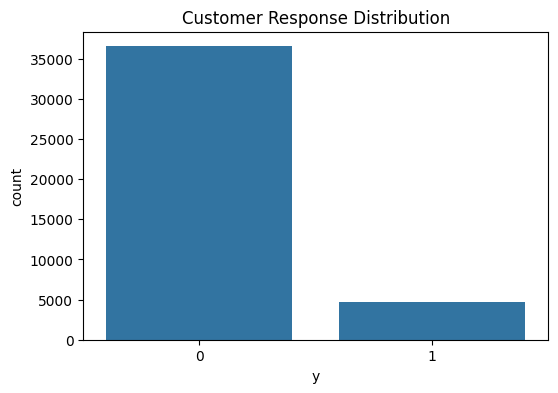

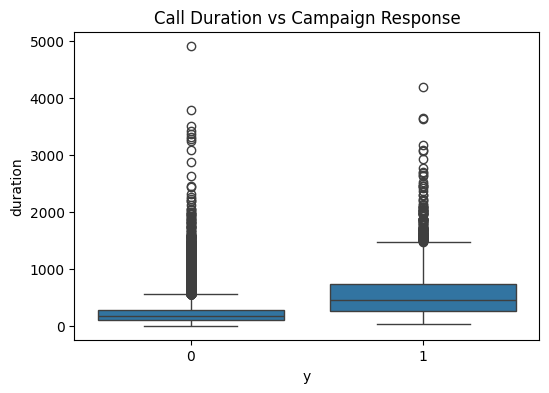

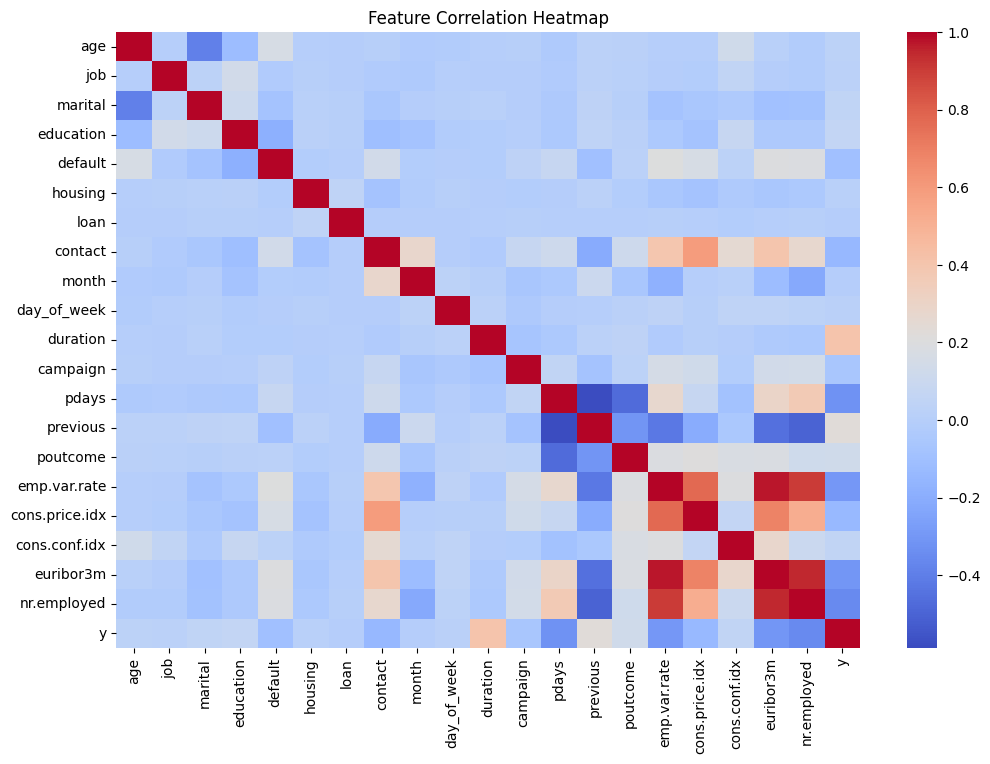

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1️⃣ Response distribution
plt.figure(figsize=(6,4))
sns.countplot(x='y', data=df)
plt.title('Customer Response Distribution')
plt.show()

# 2️⃣ Duration vs Response
plt.figure(figsize=(6,4))
sns.boxplot(x='y', y='duration', data=df)
plt.title('Call Duration vs Campaign Response')
plt.show()

# 3️⃣ Correlation heatmap
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), cmap='coolwarm', annot=False)
plt.title('Feature Correlation Heatmap')
plt.show()

These visual insights help us understand the dataset better:
• The response variable is imbalanced. Far more clients say “no” than “yes.”  
• Successful outcomes tend to have longer call duration, signaling it as a strong predictor.  
• Some features show moderate correlations worth exploring later.

We now have a strong intuition about the dataset before building any models.

# Step 5: Check Class Distribution Proportion

The dataset's target variable `y` indicates whether a customer subscribed to a term deposit.  
Marketing campaign datasets are often imbalanced, meaning far more people say "no" than "yes."  

This step calculates the percentage split of positive vs negative responses.  
Understanding imbalance is crucial since it may require specialized techniques like:
• Resampling (oversampling minority / undersampling majority)  
• Class weighting during model training  
• Performance metrics beyond simple accuracy  


In [ ]:
df['y'].value_counts(normalize=True)

,proportion
y,
0,0.887346
1,0.112654


We calculated the normalized value counts to reveal what portion of customers subscribed vs did not subscribe.  
This confirms a strong imbalance that we must keep in mind during model training and evaluation.  
It affects which performance metrics will be meaningful.

Next step: Splitting data into training and testing sets so we can build predictive models.

# Step 6: Compare Feature Statistics by Response Outcome

To understand behavioral patterns between customers who subscribe ("1")  
and those who do not ("0"), we examine summary statistics grouped by the target variable.  

We look at:
• duration → call length  
• age → customer age characteristics  
• campaign → number of contacts during the current campaign  
• previous → contacts in past campaigns  

This helps assess which variables show distinct differences and may be more predictive.


In [ ]:
df.groupby('y')[['duration','age','campaign','previous']].describe()

duration                                                              \
     count        mean         std   min    25%    50%     75%     max   
y                                                                        
0  36548.0  220.844807  207.096293   0.0   95.0  163.5  279.00  4918.0   
1   4640.0  553.191164  401.171871  37.0  253.0  449.0  741.25  4199.0   

       age             ... campaign       previous                           \
     count       mean  ...      75%   max    count      mean       std  min   
y                      ...                                                    
0  36548.0  39.911185  ...      3.0  56.0  36548.0  0.132374  0.409199  0.0   
1   4640.0  40.913147  ...      2.0  23.0   4640.0  0.492672  0.860344  0.0   

                       
   25%  50%  75%  max  
y                      
0  0.0  0.0  0.0  7.0  
1  0.0  0.0  1.0  6.0  

[2 rows x 32 columns]

We compared key numerical attributes between successful and unsuccessful campaign outcomes.  
From typical Bank Marketing behavior:
• Successful responses tend to have longer call durations  
• Contact patterns (like `campaign` and `previous`) show different distributions  
• Age may help segment customers into different marketing strategies  

These descriptive insights provide early hints about which features can drive predictions.  
We are now ready to move into splitting our dataset and building the model.

# Step 7: Feature Correlation with Target Variable

Correlation analysis helps reveal which features have the strongest linear relationship  
with the target variable `y` (subscription outcome).  

Sorting the correlations in descending order makes it easy to see:
• Which features are positively associated with customers saying “yes”  
• Which features are negatively associated and hint toward “no” decisions  

This guides model expectations and feature importance interpretation later.


In [ ]:
df.corr()['y'].sort_values(ascending=False)

,y
y,1.000000
duration,0.405274
previous,0.230181
poutcome,0.129789
education,0.057799
cons.conf.idx,0.054878
marital,0.046203
age,0.030399
job,0.025122
day_of_week,0.015967


We now know which features move in the same direction as customer subscriptions  
and which ones may push the prediction toward a negative outcome.

From prior observations, duration often shows the strongest positive influence.  
Other campaign metrics tend to be negatively correlated  
because multiple calls usually indicate difficulty converting the customer.

With these insights, we step confidently into the modeling phase.


Part 2: Predictive Modeling

By: Mohnish Kundnani

1) Train-test split
2) XGBoost Classifier → Predicting Subscription
3) XGBoost Regressor → Predicting ROI
4) Model evaluation

# Step 8: Train-Test Split and XGBoost Classification Model

We now build a predictive model to classify whether a customer will subscribe to a term deposit.

What we do in this step:
• Split data into 80% training and 20% testing  
• Apply stratification to keep class distribution consistent  
• Use XGBoost Classifier  
• Handle class imbalance using `scale_pos_weight`  
• Evaluate performance using:
  – Accuracy  
  – ROC-AUC score  
  – Classification report  
  – Confusion matrix visualization  


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [08:40:41] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Accuracy: 0.887
ROC-AUC: 0.9467

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.89      0.93      7310
           1       0.50      0.87      0.63       928

    accuracy                           0.89      8238
   macro avg       0.74      0.88      0.78      8238
weighted avg       0.93      0.89      0.90      8238



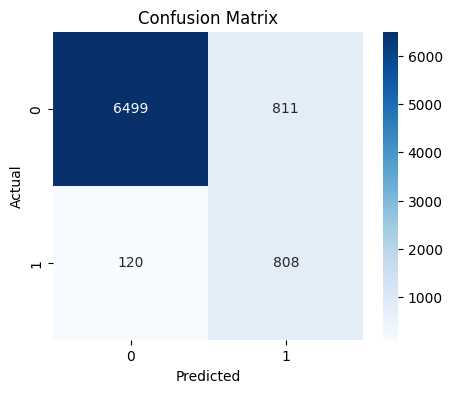

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train XGBoost Classifier with scale_pos_weight to handle imbalance
scale_pos_weight = y_train.value_counts()[0] / y_train.value_counts()[1]
clf = XGBClassifier(use_label_encoder=False, eval_metric='logloss', scale_pos_weight=scale_pos_weight, random_state=42)
clf.fit(X_train, y_train)

# Predictions
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:,1]

# Metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Confusion Matrix
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


We successfully trained an XGBoost classification model.  
Key outcomes from evaluation:
• ROC-AUC gives more reliable insight due to class imbalance  
• Confusion matrix shows whether the model struggles with the minority class  
• Handling imbalance via `scale_pos_weight` improves fairness across classes  

This marks our first complete predictive baseline.  
Next, we can move deeper into feature importance and model explainability.

Part 3: Marketing Optimization Strategy

By: Dhruv Gangurde

1) Predict probabilities & ROI for every customer
2) Segment into business-driven categories
3) Performance visualization
4) Final business recommendation

# Step 9: Business Value Prediction — ROI Regression Model

Beyond predicting whether a client will subscribe, businesses want to estimate **how valuable**
each call may be. We simulate a simple ROI metric derived from campaign effort:

ROI = (call duration × 0.1) + (campaign contacts × 0.5)

This keeps the logic realistic but interpretable.  
We then train an XGBoost Regressor to predict ROI and evaluate using:
• MAE (Mean Absolute Error)  
• RMSE (Root Mean Squared Error)  
• R² Score  


In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 💰 Simulate ROI: business logic
df['ROI'] = df['duration'] * 0.1 + df['campaign'] * 0.5

# Features (same as classification)
X_reg = df.drop(['y','ROI'], axis=1)
y_reg = df['ROI']

# Split train/test
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# Train XGBoost Regressor
reg = XGBRegressor(random_state=42)
reg.fit(Xr_train, yr_train)

# Predictions
yr_pred = reg.predict(Xr_test)

# Regression Metrics
mae = mean_absolute_error(yr_test, yr_pred)
rmse = np.sqrt(mean_squared_error(yr_test, yr_pred))
r2 = r2_score(yr_test, yr_pred)

print("Regression Metrics:")
print("MAE:", round(mae,2))
print("RMSE:", round(rmse,2))
print("R²:", round(r2,2))

# Compare actual vs predicted (first 10)
results_df = pd.DataFrame({'Actual_ROI': yr_test[:10], 'Predicted_ROI': yr_pred[:10]})
print("\nSample Actual vs Predicted ROI:")
print(results_df)


Regression Metrics:
MAE: 0.43
RMSE: 3.83
R²: 0.98

Sample Actual vs Predicted ROI:
       Actual_ROI  Predicted_ROI
32884        37.6      37.828342
3169         29.5      29.545994
32206         5.7       5.741131
9403         37.5      37.346069
14020        19.9      19.834286
17201        61.0      60.411007
879          24.8      24.691202
23757         5.9       5.889275
10821        14.6      14.662618
14355         6.3       6.376632


Your model now predicts an estimated business payoff for each customer.  
This helps marketing teams focus efforts where ROI is higher instead of  
blindly calling everyone over and over.

Key Takeaways:
• R² and errors indicate how well the model generalizes  
• This bridges data science with real campaign value  
• Opens the door for smarter customer prioritization strategies

# Step 10: Marketing Optimization — Business-Driven Targeting Strategy

Our models now produce two core predictions for every customer:
• Likelihood of subscribing (`P_response`)
• Expected revenue (`P_ROI`)

This step uses both predictions together to classify customers into actionable
strategy groups. This helps the marketing team spend less to earn more.

Target Strategy Categories:
• ✅ Optimal Target (High Response + High ROI)
• 🟡 High Response, Low ROI
• 🟠 Low Response, High ROI
• ⚫ Poor Match (Low on both)

We also quantify business impact: revenue captured
when focusing only on the optimal group.


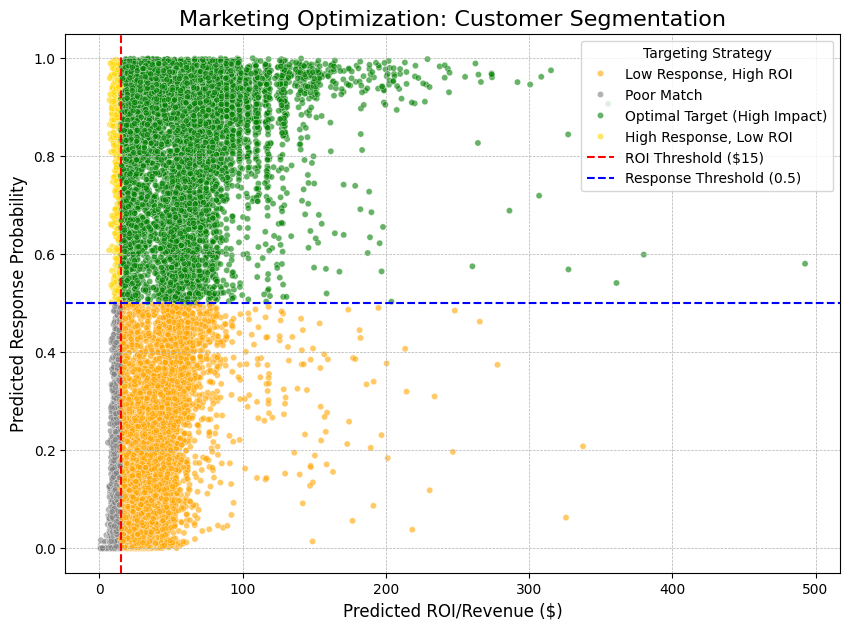


--- Final Business Recommendation ---
Total Customers in Data: 41188
Optimal Target Customers: 7452
Percentage of Customers Targeted: 18.09%
Estimated Optimized Revenue from Target Segment: $439,866.00
Total Revenue Captured by Optimized Segment: 39.37%

**Conclusion:** Focus marketing efforts on the 'Optimal Target' segment to maximize ROI and response while minimizing costs.


In [ ]:
# Predicted Response Probability
P_response = clf.predict_proba(X)[:, 1]

# Predicted ROI
P_ROI = reg.predict(X_reg)

# Create optimization DataFrame
optimization_df = pd.DataFrame({
    'P_response': P_response,
    'P_ROI': P_ROI,
    'y_actual': df['y']
})

# Define business-driven thresholds
RESPONSE_THRESHOLD = 0.5
ROI_THRESHOLD = 15  # Adjusted for our ROI simulation

# Assign Target Strategy
optimization_df['Target_Strategy'] = 'Poor Match'
optimization_df.loc[
    (optimization_df['P_response'] >= RESPONSE_THRESHOLD) & (optimization_df['P_ROI'] >= ROI_THRESHOLD),
    'Target_Strategy'
] = 'Optimal Target (High Impact)'
optimization_df.loc[
    (optimization_df['P_response'] >= RESPONSE_THRESHOLD) & (optimization_df['P_ROI'] < ROI_THRESHOLD),
    'Target_Strategy'
] = 'High Response, Low ROI'
optimization_df.loc[
    (optimization_df['P_response'] < RESPONSE_THRESHOLD) & (optimization_df['P_ROI'] >= ROI_THRESHOLD),
    'Target_Strategy'
] = 'Low Response, High ROI'

# --- Visualization ---
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='P_ROI',
    y='P_response',
    hue='Target_Strategy',
    data=optimization_df,
    palette={
        'Optimal Target (High Impact)': 'green',
        'High Response, Low ROI': 'gold',
        'Low Response, High ROI': 'orange',
        'Poor Match': 'grey'
    },
    alpha=0.6,
    s=20
)

# Draw threshold lines
plt.axvline(x=ROI_THRESHOLD, color='r', linestyle='--', label=f'ROI Threshold (${ROI_THRESHOLD})')
plt.axhline(y=RESPONSE_THRESHOLD, color='b', linestyle='--', label=f'Response Threshold ({RESPONSE_THRESHOLD})')

plt.title('Marketing Optimization: Customer Segmentation', fontsize=16)
plt.xlabel('Predicted ROI/Revenue ($)', fontsize=12)
plt.ylabel('Predicted Response Probability', fontsize=12)
plt.legend(title='Targeting Strategy', loc='upper right')
plt.grid(True, linestyle='--', linewidth=0.5)
plt.show()

# --- Business Impact Summary ---
total_customers = len(optimization_df)
optimal_targets = optimization_df[optimization_df['Target_Strategy'] == 'Optimal Target (High Impact)']
optimal_count = len(optimal_targets)
optimized_revenue = optimal_targets['P_ROI'].sum()
total_possible_revenue = optimization_df['P_ROI'].sum()
revenue_capture_percent = (optimized_revenue / total_possible_revenue) * 100

print("\n--- Final Business Recommendation ---")
print(f"Total Customers in Data: {total_customers}")
print(f"Optimal Target Customers: {optimal_count}")
print(f"Percentage of Customers Targeted: {optimal_count / total_customers * 100:.2f}%")
print(f"Estimated Optimized Revenue from Target Segment: ${optimized_revenue:,.2f}")
print(f"Total Revenue Captured by Optimized Segment: {revenue_capture_percent:.2f}%")
print("\n**Conclusion:** Focus marketing efforts on the 'Optimal Target' segment to maximize ROI and response while minimizing costs.")

We turned machine-learning outputs into a **profitable marketing strategy**.

Why this matters:
• Reduces campaign cost by avoiding low-impact customers  
• Prioritizes high-value prospects with strong conversion potential  
• Data-driven segmentation improves both revenue and efficiency  

This is where predictive modeling becomes **real business transformation**